# Temperature & Semantic Scopes — Evo 2 (StripedHyena 2)

Adaptation of [JacobianScopes](https://github.com/AntonioLiu97/JacobianScopes) for the **Evo 2** genomic foundation model.

### What this notebook computes

| Scope | Definition | Intuition |
|---|---|---|
| **Temperature Scope** | For a fixed *target* position `t`, sweep the residual injection over every *source* position `s` and record `‖∇_residual loss(t)‖`. | Which source positions most strongly influence the hidden state at the target? |
| **Semantic Scope** | Cosine similarity of gradient vectors across source positions, for a fixed target. | Which source positions exert influence in the *same direction*? |

### Key Evo 2 differences vs the LLaMA notebook

| Aspect | LLaMA / Pythia | Evo 2 |
|---|---|---|
| Loading | `AutoModelForCausalLM` | `Evo2('evo2_7b')` |
| Tokenizer | HuggingFace subword | `CharLevelTokenizer` — 1 token = 1 byte, vocab = 512 |
| Token decoding | `tokenizer.decode(id)` | `chr(id)` |
| BOS/EOS padding | `bos_token_id` | No special tokens |
| `input_ids` dtype | `torch.long` | `torch.int32` |
| Attention mask | Required | Not used (fully convolutional) |
| `inputs_embeds` | Direct arg | Injected via forward hook |
| `grad_idx` | List of all positions | **Single int** (swept in a loop) |

### 1 · Imports and device setup

In [1]:
import os
# MUST come before any evo2 / TransformerEngine import to disable NVRTC JIT
gpu_n = '0'
# os.environ["NVTE_DISABLE_NVRTC"] = gpu_n

os.environ['CUDA_VISIBLE_DEVICES'] = gpu_n



import gc
import torch
import torch.nn.functional as F
from torch import nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import Normalize as Norm, LogNorm as Log_Norm
from IPython.display import HTML, display
from tqdm.notebook import tqdm
import random

from Bio import SeqIO

import seaborn as sns

import JCBScope_evo2_utils as JCBScope
from JCScope_evo2_utils_distplot import gather_scope_data, plot_scope_distribution

### 2 · GPU memory cleanup

In [2]:
if torch.cuda.is_available():
    print('Empting cuda cache')
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    gc.collect()

    device = 'cuda:0'
else:
    print('Using cpu')
    device = 'cpu'

Empting cuda cache


### 3 · Load Evo 2

Available model names:
- `'evo2_7b'`       – 7 B parameters (no FP8, any recent GPU)
- `'evo2_1b_base'`  – 1 B parameters (FP8, Hopper GPU required)
- `'evo2_40b'`      – 40 B parameters (FP8, Hopper GPU required)

In [3]:
from evo2 import Evo2


model_name = 'evo2_7b'

evo2_wrapper = Evo2(model_name)
backbone     = JCBScope.get_backbone(evo2_wrapper)
tokenizer    = evo2_wrapper.tokenizer

backbone.eval()
print('Loaded:', model_name)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Found complete file in repo: evo2_7b.pt


100%|████████████████████████████████████████████████████████████████| 32/32 [00:00<00:00, 307.27it/s]


Extra keys in state_dict: {'blocks.16.mixer.mixer.filter.t', 'blocks.3.mixer.dense._extra_state', 'blocks.10.mixer.attn._extra_state', 'blocks.24.mixer.attn._extra_state', 'blocks.9.mixer.mixer.filter.t', 'blocks.23.mixer.mixer.filter.t', 'blocks.20.mixer.mixer.filter.t', 'blocks.17.mixer.attn._extra_state', 'blocks.27.mixer.mixer.filter.t', 'blocks.31.mixer.dense._extra_state', 'blocks.10.mixer.dense._extra_state', 'blocks.30.mixer.mixer.filter.t', 'blocks.2.mixer.mixer.filter.t', 'blocks.3.mixer.attn._extra_state', 'unembed.weight', 'blocks.6.mixer.mixer.filter.t', 'blocks.24.mixer.dense._extra_state', 'blocks.17.mixer.dense._extra_state', 'blocks.31.mixer.attn._extra_state', 'blocks.13.mixer.mixer.filter.t'}


/home/bertolo/.local/lib/python3.11/site-packages/vortex/model/model.py:905: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  te_fp8_meta = torch.load(extra_state_value)
/scrat

Loaded: evo2_7b


### 4 · Set input sequence and scope mode

Evo 2 uses a **byte-level tokenizer**: each character maps directly to its ASCII byte value.  No BOS/EOS tokens exist — pad with null byte `0x00` if fixed-length inputs are needed.

In [4]:
NUCLEOTIDES = ['A', 'C', 'G', 'T']
BUFFER_LEN = 24
LABEL_LEN  = 24

def sample_label_nucleotides():
    """
    Sample three distinct nucleotides without replacement from {A, C, G, T}:
      - buffer_nuc  : used for the 24-nt spacer between a sequence and its label
      - label_nuc_0 : label nucleotide representing class 0
      - label_nuc_1 : label nucleotide representing class 1

    Re-sampling per trial ensures no fixed nucleotide is systematically
    associated with a particular class, eliminating nucleotide-bias artifacts.

    Returns
    -------
    buffer_nuc  : str   single nucleotide character for the buffer
    label_nuc_0 : str   single nucleotide character for class 0
    label_nuc_1 : str   single nucleotide character for class 1
    """
    chosen = random.sample(NUCLEOTIDES, 3)
    return chosen[0], chosen[1], chosen[2]

def make_label_string(buffer_nuc, label_nuc, buffer_len=None, label_len=None):
    """
    Construct the label suffix appended to each in-context training example.

    Structure:  [buffer_nuc × buffer_len] + [label_nuc × label_len]

    The buffer provides a clear separator between the biological sequence and
    the classification label, reducing any ambiguity at the junction.

    Parameters
    ----------
    buffer_nuc  : str   nucleotide character repeated buffer_len times
    label_nuc   : str   nucleotide character repeated label_len times (the class token)
    buffer_len  : int   length of the buffer region (defaults to BUFFER_LEN if None)
    label_len   : int   length of the label region  (defaults to LABEL_LEN  if None)

    Returns
    -------
    str : the full label suffix (buffer + label run)
    """
    if buffer_len is None:
        buffer_len = BUFFER_LEN
    if label_len is None:
        label_len = LABEL_LEN
    return buffer_nuc * buffer_len + label_nuc * label_len

def build_few_shot_prefix(
    context_examples,
    buffer_nuc,
    label_nuc_0,
    label_nuc_1,
    buffer_len=None,
    label_len=None,
):
    """
    Construct the few-shot prefix from in-context training examples.

    Each example is: <sequence><buffer_nuc × buffer_len><label_nuc × label_len>

    The label nucleotide depends on the example's class:
      - class 0 → label_nuc_0
      - class 1 → label_nuc_1

    Parameters
    ----------
    context_examples : list of (sequence: str, class_idx: int)
        Balanced list of training sequences and their class indices (0 or 1).
    buffer_nuc       : str   buffer nucleotide (see sample_label_nucleotides)
    label_nuc_0      : str   label nucleotide for class 0
    label_nuc_1      : str   label nucleotide for class 1
    buffer_len  : int   length of buffer region (defaults to BUFFER_LEN if None)
    label_len   : int   length of label region  (defaults to LABEL_LEN  if None)

    Returns
    -------
    str : concatenated few-shot prefix (no separator between examples)
    """
    if buffer_len is None:
        buffer_len = BUFFER_LEN
    if label_len is None:
        label_len = LABEL_LEN
    label_nucs = [label_nuc_0, label_nuc_1]
    parts = []
    for seq, class_idx in context_examples:
        label_suffix = make_label_string(buffer_nuc, label_nucs[class_idx], buffer_len, label_len)
        parts.append(seq + label_suffix)
    return "".join(parts)

def build_candidate_prompt(prefix, query_seq, buffer_nuc, candidate_label_nuc,
                            buffer_len=None, label_len=None):
    """
    Build a complete candidate prompt for perplexity scoring.

    Structure:
        <few-shot prefix> + <query_seq> + <buffer> + <candidate label run>

    Two candidate prompts are built per test query: one for class 0 and one
    for class 1.  The model's perplexity is computed over the final label_len
    tokens (the label run only, not the buffer), and the candidate with lower
    perplexity is selected as the prediction.

    Parameters
    ----------
    prefix               : str   pre-built few-shot prefix
    query_seq            : str   the test sequence to classify
    buffer_nuc           : str   buffer nucleotide
    candidate_label_nuc  : str   label nucleotide for this candidate class
    buffer_len           : int   length of buffer region (defaults to BUFFER_LEN if None)
    label_len            : int   length of label region  (defaults to LABEL_LEN  if None)

    Returns
    -------
    str : full prompt string including the candidate label
    """
    if buffer_len is None:
        buffer_len = BUFFER_LEN
    if label_len is None:
        label_len = LABEL_LEN
    label_suffix = make_label_string(buffer_nuc, candidate_label_nuc, buffer_len, label_len)
    return prefix + query_seq + label_suffix


In [5]:
import random
from collections import defaultdict
from Bio import SeqIO

# ── config ──────────────────────────────────────────────────────────────────
TRAIN_FASTA  = "data/mrna_train.fna"
TEST_FASTA   = "data/mrna_test.fna"
N            = 32                        # shots per class
CLASS_NAMES  = ['tata', 'neutral']
BUFFER_LEN   = 24
LABEL_LEN    = 24
random.seed(42)

# ── load train pool ──────────────────────────────────────────────────────────
train_pool = defaultdict(list)
for record in SeqIO.parse(TRAIN_FASTA, "fasta"):
    raw_label = next(
        (p.split('=')[1] for p in record.description.split() if p.startswith('label=')), None
    )
    if raw_label in CLASS_NAMES:
        train_pool[raw_label].append((record.id, str(record.seq).upper()))

# ── grab the first test sequence ─────────────────────────────────────────────
test_record = next(
    r for r in SeqIO.parse(TEST_FASTA, "fasta")
    if any(p.split('=')[1] in CLASS_NAMES
           for p in r.description.split() if p.startswith('label='))
)
query_seq  = str(test_record.seq).upper()
true_label = next(p.split('=')[1] for p in test_record.description.split() if p.startswith('label='))

# ── sample context + nucleotide assignments ───────────────────────────────────
context = []
for class_idx, class_name in enumerate(CLASS_NAMES):
    for _, seq in random.sample(train_pool[class_name], min(N, len(train_pool[class_name]))):
        context.append((seq, class_idx))
random.shuffle(context)

buffer_nuc, label_nuc_0, label_nuc_1 = sample_label_nucleotides()

# ── build the two candidate prompts ──────────────────────────────────────────
prefix   = build_few_shot_prefix(context, buffer_nuc, label_nuc_0, label_nuc_1, BUFFER_LEN, LABEL_LEN)
prompt_0 = build_candidate_prompt(prefix, query_seq, buffer_nuc, label_nuc_0, BUFFER_LEN, LABEL_LEN)
prompt_1 = build_candidate_prompt(prefix, query_seq, buffer_nuc, label_nuc_1, BUFFER_LEN, LABEL_LEN)

print(f"True label : {true_label}")
print(f"Nucleotides: buffer={buffer_nuc}  class0={label_nuc_0}  class1={label_nuc_1}")
print(f"Prompt-0 length: {len(prompt_0)} chars")
print(f"Prompt-1 length: {len(prompt_1)} chars")
print(f"\n--- Prompt-0 (tail 120 chars) ---\n...{prompt_0[-120:]}")
print(f"\n--- Prompt-1 (tail 120 chars) ---\n...{prompt_1[-120:]}")

True label : neutral
Nucleotides: buffer=C  class0=A  class1=T
Prompt-0 length: 2314 chars
Prompt-1 length: 2314 chars

--- Prompt-0 (tail 120 chars) ---
...TACCCCCCCCCCCCCCCCCCCCCCCCTTTTTTTTTTTTTTTTTTTTTTTTTTAATTGCAACTGCGAGTTTGACCCCCCCCCCCCCCCCCCCCCCCCAAAAAAAAAAAAAAAAAAAAAAAA

--- Prompt-1 (tail 120 chars) ---
...TACCCCCCCCCCCCCCCCCCCCCCCCTTTTTTTTTTTTTTTTTTTTTTTTTTAATTGCAACTGCGAGTTTGACCCCCCCCCCCCCCCCCCCCCCCCTTTTTTTTTTTTTTTTTTTTTTTT


In [6]:
# mode = 'Temperature'
mode = 'Semantic'

if mode not in ['Temperature', 'Semantic']:
    raise ValueError(f"mode must be 'Temperature' or 'Semantic', got {mode!r}")


In [7]:
# ── Example sequences ────────────────────────────────────────────────────
# Promoter-like TATA-box followed by a coding-region stub
# string = 'TATAAAAGGCTAGCATGCGTACGATCGATCGATCGTTAG'

# Splice-donor / acceptor motif (GT…AG rule)
# string = 'ATCGATCGATCGGTAAGTATCGATCGATCGATCGATCGAGC'

# Simple repetitive element
# string = 'ATGATGATGATGATGATGATGATGATGATGATGATGATGATG'

# Coding sequence: ATG … stop codon TGA
# string = 'ATGCGTACGATCGATCGATCGTTCAACGATCGATCGATCGTGA'

front_pad = 0   # prepend this many null-byte (0x00) tokens
back_pad  = 0   # append  this many null-byte (0x00) tokens

In [8]:
string = prompt_0

### 5 · Tokenise and inspect

In [17]:
# Evo 2 tokenizer returns list[np.uint8]; cast to plain int
raw_ids = [int(t) for t in tokenizer.tokenize(string)]

PAD_ID = 0
input_ids_list = [PAD_ID] * front_pad + raw_ids + [PAD_ID] * back_pad

# dtype=torch.int32 required by Vortex VocabParallelEmbedding
input_ids = torch.tensor([input_ids_list], dtype=torch.int32).to(device)

vocab_size = JCBScope.get_embedding_layer(backbone).weight.shape[0]
assert input_ids.max() < vocab_size, (
    f'Token id {input_ids.max().item()} out of range [0, {vocab_size})')

seq_len = input_ids.size(1)

# Each token id is an ASCII byte; chr() decodes it
decoded_tokens = [chr(t.item()) for t in input_ids[0]]

print(f'seq_len   : {seq_len}')
print(f'vocab_size: {vocab_size}')
print('\nPos  TokenID  Char')
for i, tok in enumerate(input_ids[0]):
    print(f'{i:3d}    {tok.item():3d}    {chr(tok.item())!r}')
print('\ndecoded_tokens:', decoded_tokens)

seq_len   : 13836
vocab_size: 512

Pos  TokenID  Char
  0     67    'C'
  1     67    'C'
  2     65    'A'
  3     67    'C'
  4     67    'C'
  5     65    'A'
  6     65    'A'
  7     71    'G'
  8     65    'A'
  9     84    'T'
 10     84    'T'
 11     67    'C'
 12     67    'C'
 13     67    'C'
 14     65    'A'
 15     65    'A'
 16     84    'T'
 17     84    'T'
 18     65    'A'
 19     84    'T'
 20     67    'C'
 21     65    'A'
 22     67    'C'
 23     67    'C'
 24     65    'A'
 25     84    'T'
 26     84    'T'
 27     67    'C'
 28     67    'C'
 29     84    'T'
 30     65    'A'
 31     71    'G'
 32     71    'G'
 33     65    'A'
 34     71    'G'
 35     67    'C'
 36     67    'C'
 37     67    'C'
 38     84    'T'
 39     65    'A'
 40     71    'G'
 41     84    'T'
 42     71    'G'
 43     67    'C'
 44     67    'C'
 45     84    'T'
 46     71    'G'
 47     71    'G'
 48     65    'A'
 49     84    'T'
 50     71    'G'
 51     67    'C'
 52     71

### 6 · Choose the target position

`loss_position` is the token whose hidden state (Temperature Scope) or next-token CE loss (Semantic Scope) we differentiate.  It must satisfy `front_pad ≤ loss_position < seq_len − 1`.

The **source sweep** will inject the gradient residual at every position `s ∈ [0, seq_len)` in turn, giving one gradient vector per source position.

In [18]:
# Target position: whose hidden state / CE loss we differentiate
loss_position = seq_len - 2   # last position that has a 'next token'

# Positions to sweep as residual injection point (all by default)
source_positions = list(range(seq_len))

hidden_norm_as_loss = (mode == 'Temperature')
unnormalized_logits = True

print(f'loss_position  : {loss_position}  (char {decoded_tokens[loss_position]!r})')
print(f'next-token char: {decoded_tokens[loss_position + 1]!r}')
print(f'source sweep   : positions {source_positions[0]}…{source_positions[-1]}')
print(f'mode           : {mode}')

loss_position  : 13834  (char 'A')
next-token char: 'A'
source sweep   : positions 0…13835
mode           : Semantic


### 7 · Resolve model dimension

In [19]:
embedding_layer = JCBScope.get_embedding_layer(backbone)
d_model = embedding_layer.weight.shape[1]
presence = torch.ones(seq_len, dtype=torch.float32, device=device)
print(f'd_model : {d_model}')

d_model : 4096


### 8 · Quick single forward pass — next-token prediction

Before the full sweep, run one pass with zero residual at `loss_position` to inspect the model's top-k predictions.

In [10]:
residual_0 = nn.Parameter(torch.zeros(d_model, device=device))
fp0 = JCBScope.customize_forward_pass(
    backbone  = backbone,
    residual  = residual_0,
    presence  = presence,
    input_ids = input_ids,
    grad_idx  = loss_position,   # inject at the target position itself
)
loss0, logits0 = fp0(
    loss_position       = loss_position,
    hidden_norm_as_loss = hidden_norm_as_loss,
    unnormalized_logits = unnormalized_logits,
)
print(f'loss at position {loss_position}: {loss0.item():.4f}')

k = 7
logit_vec = logits0[loss_position].detach().float()
probs     = torch.softmax(logit_vec, dim=-1)
top_probs, top_idx = torch.topk(probs, k)
top_tokens = [repr(chr(i.item())) for i in top_idx]

plt.figure(figsize=(6, 1.5), dpi=100)
plt.bar(range(k), top_probs.cpu().numpy(), tick_label=top_tokens, color='red')
plt.xticks(rotation=90, fontweight='bold', fontsize=18)
plt.ylabel('Probability', fontweight='bold', fontsize=16)
plt.yticks(fontweight='bold', fontsize=12)
plt.gca().yaxis.set_major_locator(plt.MaxNLocator(nbins=2))
plt.title(f'Top {k} predictions after position {loss_position} '
          f'({decoded_tokens[loss_position]!r})', fontsize=10)
plt.tight_layout()
plt.show()

### 9 · Full source sweep — one gradient per source position

For each source position `s` in `source_positions`:
1. Create a fresh `residual_s` parameter of shape `[d_model]`, zeroed.
2. Build a `forward_pass` with `grad_idx=s` (residual injected *at s*).
3. Compute the loss at `loss_position` and backpropagate.
4. Record `‖∇_{residual_s} loss‖` as the influence of source `s`.

This gives the same information as the original LLaMA notebook's `[L, d]` residual gradient, but one position at a time — which is the correct API for `JCBScope_evo2_utils`.

In [94]:
all_grads      = []   # list of [d_model] tensors
grad_norms     = []   # scalar ‖∇‖ per source position

for s in tqdm(source_positions, desc=f'{mode} sweep'):
    residual_s = nn.Parameter(torch.zeros(d_model, device=device))
    fp_s = JCBScope.customize_forward_pass(
        backbone  = backbone,
        residual  = residual_s,
        presence  = presence,
        input_ids = input_ids,
        grad_idx  = s,
    )
    loss_s, _ = fp_s(
        loss_position       = loss_position,
        hidden_norm_as_loss = hidden_norm_as_loss,
        unnormalized_logits = unnormalized_logits,
        tie_input_output_embed = False,
    )
    g = torch.autograd.grad(loss_s, residual_s)[0].detach().cpu()
    all_grads.append(g)
    grad_norms.append(g.norm().item())

# Stack: [seq_len, d_model]
grad_matrix = torch.stack(all_grads)          # [L, d]
grad_magnitude = torch.tensor(grad_norms)      # [L]

print('grad_matrix shape :', grad_matrix.shape)

Semantic sweep: 100%|█████████████████████████| 970/970 [02:12<00:00,  7.33it/s]

grad_matrix shape : torch.Size([970, 4096])


### 10 · Temperature Scope profile — bar chart




In [95]:
x_labels = [repr(decoded_tokens[s]) for s in source_positions]

fig, ax = plt.subplots(figsize=(max(6, seq_len * 0.45), 3), dpi=120)
ax.bar(range(seq_len), grad_magnitude.numpy(), color='steelblue')
ax.axvline(loss_position, color='red', linestyle='--', linewidth=1.2,
           label=f'loss_position={loss_position}')
ax.set_xticks(range(seq_len))
ax.set_xticklabels(x_labels, rotation=90, fontfamily='monospace', fontsize=10)
ax.set_ylabel('‖∇ residual‖', fontweight='bold')
ax.set_title(f'{mode} Scope  ·  target pos={loss_position}  ·  model={model_name}',
             fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 11 · Attribution visualisation — rounded token boxes

In [96]:
log_color = False   # True → log-scale colour mapping

cmap = plt.get_cmap('Blues')
eps  = 1e-9
log_norm = Log_Norm(vmin=max(grad_magnitude.min().item(), eps),
                    vmax=grad_magnitude.max().item())
norm = Norm(vmin=grad_magnitude.min().item(),
            vmax=grad_magnitude.max().item())

colors = cmap(log_norm(grad_magnitude.numpy()) if log_color
              else norm(grad_magnitude.numpy()))

# Highlight the predicted token (loss_position + 1)
bar_idx = loss_position + 1 if (loss_position + 1) < seq_len else loss_position

tick_labels = list(decoded_tokens)
if hidden_norm_as_loss:
    tick_labels[bar_idx] = '<predicted>'

def rgba_to_css(rgba):
    return (f'rgba({int(rgba[0]*255)},{int(rgba[1]*255)},'
            f'{int(rgba[2]*255)},{rgba[3]:.2f})')

def get_text_color(bg_rgba):
    lum = 0.299*bg_rgba[0] + 0.587*bg_rgba[1] + 0.114*bg_rgba[2]
    return 'white' if lum < 0.5 else 'black'

html_parts = []
for i, (tok, col) in enumerate(zip(tick_labels, colors)):
    bg   = rgba_to_css(col)
    fg   = get_text_color(col)
    if i == bar_idx:
        bg, fg = 'red', 'white'
    disp = tok if tok.strip() else '·'
    html_parts.append(
        f'<span style="background-color:{bg};color:{fg};'
        f'padding:0px 9px;margin:2px;border-radius:8px;'
        f'font-family:monospace;font-size:16px;'
        f'display:inline-block;font-weight:bold;">{disp}</span>'
    )

html_str = ('<div style="background:white;padding:20px;border-radius:8px;'
             'line-height:2.5;max-width:900px;">\n'
             + ''.join(html_parts) + '\n</div>')
display(HTML(html_str))

### 12 · Attribution visualisation — inline (no gaps)

In [97]:
html_parts2 = []
for i, (tok, col) in enumerate(zip(tick_labels, colors)):
    bg   = rgba_to_css(col)
    fg   = get_text_color(col)
    if i == bar_idx:
        bg, fg = 'red', 'white'
    html_parts2.append(
        f'<span style="background-color:{bg};color:{fg};'
        f'padding:0px 0px;margin:0px;border-radius:0px;'
        f'font-family:monospace;font-size:16px;'
        f'display:inline-block;font-weight:bold;white-space:pre;">{tok}</span>'
    )

html_str2 = ('<div style="background:white;padding:20px;border-radius:8px;'
              'line-height:2.5;max-width:900px;">\n'
              + ''.join(html_parts2) + '\n</div>')
display(HTML(html_str2))

### 13 · Colour bar

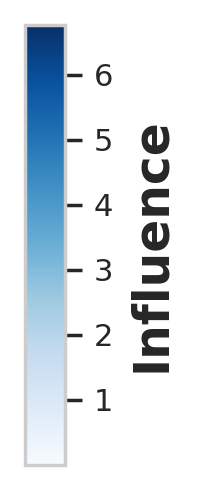

In [98]:
fig_bar, ax_bar = plt.subplots(figsize=(0.4, 2.2), dpi=250)
fig_bar.subplots_adjust(left=0.3, right=0.7, bottom=0.1, top=0.9)
mpl.colorbar.ColorbarBase(
    ax_bar,
    cmap=cmap,
    norm=log_norm if log_color else norm,
    orientation='vertical'
).set_label('Influence', fontsize=14, fontweight='bold')
plt.show()

### 14 · Semantic Scope — cosine similarity heatmap

The cosine similarity of gradient vectors at source positions `s₁` and `s₂` measures whether they influence the target in the **same direction** in embedding space.  High similarity = semantically correlated influence.

In [99]:
norms_mat  = grad_matrix.norm(dim=-1, keepdim=True).clamp(min=1e-9)
grad_unit  = grad_matrix / norms_mat           # [L, d]
cosine_sim = grad_unit @ grad_unit.T           # [L, L]

fig, ax = plt.subplots(
    figsize=(max(5, seq_len * 0.35), max(5, seq_len * 0.35)),
    dpi=120
)
im = ax.imshow(cosine_sim.numpy(), vmin=-1, vmax=1, cmap='RdBu_r')
plt.colorbar(im, ax=ax, label='Cosine similarity')
ax.set_xticks(range(seq_len))
ax.set_yticks(range(seq_len))
ax.set_xticklabels([repr(c) for c in decoded_tokens],
                   rotation=90, fontfamily='monospace', fontsize=9)
ax.set_yticklabels([repr(c) for c in decoded_tokens],
                   fontfamily='monospace', fontsize=9)
ax.set_title(f'Semantic Scope (cosine sim)  ·  target={loss_position}  ·  {model_name}',
             fontweight='bold')
plt.tight_layout()
plt.show()

### 15 · Label token influence attribution

Computes the Jacobian-based Temperature or Semantic scope for the last N
tokens of a sequence, then renders a distribution plot:

  x-axis  – every position in the *full* original sequence (labelled by char)
  y-axis  – influence value (‖∇ residual‖ for Temperature; cosine-sim for Semantic)
  hue     – one distribution curve / scatter per target token (the N "last" ones)


In [9]:
raw_ids  = [int(t) for t in tokenizer.tokenize(string)]
input_ids = torch.tensor([raw_ids], dtype=torch.int32).to(device)

results = gather_scope_data(backbone, input_ids, N=24, mode="Semantic", device=device)

Semantic sweep (24 targets): 100%|█████████████████████████████████| 24/24 [4:42:20<00:00, 705.84s/it]


In [10]:
"""
jacobian_scope_distribution.py
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    results = gather_scope_data(backbone, input_ids, N, mode, device)
    fig     = plot_scope_distribution(results)
    fig     = plot_scope_distribution_annotated(results, TL, NL, B, l)
    fig     = plot_scope_ridge(results, TL, NL, B, l)
"""

import gc
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
from tqdm import tqdm

import JCBScope_evo2_utils as JCBScope


# ─────────────────────────────────────────────────────────────────────────────
# 1. Data gathering
# ─────────────────────────────────────────────────────────────────────────────

def gather_scope_data(
    backbone,
    input_ids: torch.Tensor,
    N: int,
    mode: str = "Temperature",
    unnormalized_logits: bool = True,
    device: torch.device = None,
) -> dict:
    """
    Compute grad_magnitude = ‖∇_{residual_s} loss‖ for every source position s,
    repeated for each of the last N valid target tokens.

    A valid target satisfies loss_position <= seq_len - 2 (needs a next token).
    Always returns exactly min(N, seq_len - 1) curves.

    Returns
    -------
    dict:
        seq_len, decoded_tokens, target_positions,
        grad_magnitudes (dict[int -> np.ndarray[seq_len]]), mode
    """
    if mode not in ("Temperature", "Semantic"):
        raise ValueError(f"mode must be 'Temperature' or 'Semantic', got {mode!r}")
    if device is None:
        device = input_ids.device

    seq_len = input_ids.size(1)
    if N < 1:
        raise ValueError(f"N must be >= 1, got {N}")

    # Last N positions satisfying loss_position <= seq_len - 2
    max_target       = seq_len - 2
    all_valid        = list(range(0, max_target + 1))   # [0 .. seq_len-2]
    target_positions = all_valid[-N:]                   # always exactly min(N, seq_len-1)

    decoded_tokens      = [chr(t.item()) for t in input_ids[0]]
    embedding_layer     = JCBScope.get_embedding_layer(backbone)
    d_model             = embedding_layer.weight.shape[1]
    presence            = torch.ones(seq_len, dtype=torch.float32, device=device)
    hidden_norm_as_loss = (mode == "Temperature")
    grad_magnitudes     = {}

    for loss_pos in tqdm(target_positions, desc=f"{mode} sweep ({len(target_positions)} targets)"):
        grad_norms = []
        for s in range(seq_len):
            residual_s = nn.Parameter(torch.zeros(d_model, device=device))
            fp_s = JCBScope.customize_forward_pass(
                backbone=backbone, residual=residual_s,
                presence=presence, input_ids=input_ids, grad_idx=s,
            )
            loss_s, _ = fp_s(
                loss_position=loss_pos,
                hidden_norm_as_loss=hidden_norm_as_loss,
                unnormalized_logits=unnormalized_logits,
                tie_input_output_embed=False,
            )
            g = torch.autograd.grad(loss_s, residual_s)[0].detach().cpu()
            grad_norms.append(g.norm().item())

        grad_magnitudes[loss_pos] = np.array(grad_norms)
        torch.cuda.empty_cache()
        gc.collect()

    return dict(
        seq_len=seq_len,
        decoded_tokens=decoded_tokens,
        target_positions=target_positions,
        grad_magnitudes=grad_magnitudes,
        mode=mode,
    )


# ─────────────────────────────────────────────────────────────────────────────
# 2. Plain distribution plot
# ─────────────────────────────────────────────────────────────────────────────

def plot_scope_distribution(
    results: dict,
    figsize: tuple = (10, 4),
    palette: str = "flare",
    fill_alpha: float = 0.25,
    line_alpha: float = 0.85,
    title: str = None,
) -> plt.Figure:
    """
    Filled line plot — one curve per target token.

    x-axis : source position index
    y-axis : ‖∇ residual‖ influence score
    hue    : one filled curve per target token
    """
    seq_len          = results["seq_len"]
    decoded_tokens   = results["decoded_tokens"]
    target_positions = results["target_positions"]
    grad_magnitudes  = results["grad_magnitudes"]
    mode             = results["mode"]

    x      = np.arange(seq_len)
    colors = sns.color_palette(palette, n_colors=len(target_positions))

    fig, ax = plt.subplots(figsize=figsize, dpi=120)

    for color, loss_pos in zip(colors, target_positions):
        vec   = grad_magnitudes[loss_pos]
        label = f"pos {loss_pos} ({repr(decoded_tokens[loss_pos])})"
        ax.plot(x, vec, color=color, alpha=line_alpha, linewidth=1.5, label=label)
        ax.fill_between(x, vec, alpha=fill_alpha, color=color)

    ax.set_xlabel("Input Sequence Position")
    ax.set_ylabel("Influence")
    ax.set_title(title or f"{mode} Scope — influence on last {len(target_positions)} tokens",
                 fontweight="bold")
    ax.legend(title="Target token", loc="upper left", framealpha=0.8)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    return fig


# ─────────────────────────────────────────────────────────────────────────────
# 3. Annotated distribution plot
# ─────────────────────────────────────────────────────────────────────────────

def _find_regions(decoded_tokens: list[str], nucleotide: str, l: int) -> list[tuple[int, int]]:
    """
    Find all runs of `nucleotide` that are >= l long.
    Returns list of (start, end) inclusive position pairs.
    """
    seq = "".join(decoded_tokens)
    runs, i, n = [], 0, len(seq)
    while i < n:
        if seq[i] == nucleotide:
            j = i
            while j < n and seq[j] == nucleotide:
                j += 1
            if j - i >= l:
                runs.append((i, j - 1))
            i = j
        else:
            i += 1
    return runs


def _find_tata_boxes(decoded_tokens: list[str]) -> list[tuple[int, int]]:
    """
    Find all occurrences of the TATA-box motif TATAWAWR
    where W = A or T, R = A or G.
    Returns list of (start, end) inclusive position pairs (length 8 each).
    """
    import re
    seq     = "".join(decoded_tokens)
    pattern = re.compile(r"(?=TATA[AT][AT][AG])")   # lookahead for overlapping matches
    return [(m.start(), m.start() + 7) for m in pattern.finditer(seq)]


def plot_scope_distribution_annotated(
    results: dict,
    TL: str,
    NL: str,
    B: str,
    l: int,
    figsize: tuple = (12, 4),
    palette: str = "flare",
    fill_alpha: float = 0.25,
    line_alpha: float = 0.85,
    buffer_color: str = "gold",
    neutral_label_color: str = "red",
    target_label_color: str = "green",
    region_alpha: float = 0.40,
    title: str = None,
) -> plt.Figure:
    """
    Filled-curve plot with shaded background regions marking buffer,
    target-label, and neutral-label nucleotide blocks.

    Parameters
    ----------
    results             : dict from gather_scope_data()
    TL                  : target label nucleotide character, e.g. 'C'
    NL                  : neutral label nucleotide character, e.g. 'T'
    B                   : buffer nucleotide character, e.g. 'A'
    l                   : length of each buffer / label block
    buffer_color        : shade colour for buffer regions
    neutral_label_color : shade colour for neutral label regions
    target_label_color  : shade colour for target label regions
    region_alpha        : transparency of the shaded bands
    """
    seq_len          = results["seq_len"]
    decoded_tokens   = results["decoded_tokens"]
    target_positions = results["target_positions"]
    grad_magnitudes  = results["grad_magnitudes"]
    mode             = results["mode"]

    x      = np.arange(seq_len)
    colors = sns.color_palette(palette, n_colors=len(target_positions))

    fig, ax = plt.subplots(figsize=figsize, dpi=120)

    # ── Shaded regions (drawn first, behind curves) ───────────────────────────
    buffer_regions        = _find_regions(decoded_tokens, B,  l)
    target_label_regions  = _find_regions(decoded_tokens, TL, l)
    neutral_label_regions = _find_regions(decoded_tokens, NL, l)
    tata_regions          = _find_tata_boxes(decoded_tokens)

    for start, end in buffer_regions:
        ax.axvspan(start, end, color=buffer_color,        alpha=region_alpha, linewidth=0)
    for start, end in target_label_regions:
        ax.axvspan(start, end, color=target_label_color,  alpha=region_alpha, linewidth=0)
    for start, end in neutral_label_regions:
        ax.axvspan(start, end, color=neutral_label_color, alpha=region_alpha, linewidth=0)
    for start, end in tata_regions:
        ax.axvspan(start, end, color="lightblue",         alpha=region_alpha, linewidth=0)

    # ── Curves ───────────────────────────────────────────────────────────────
    for color, loss_pos in zip(colors, target_positions):
        vec   = grad_magnitudes[loss_pos]
        label = f"pos {loss_pos} ({repr(decoded_tokens[loss_pos])})"
        ax.plot(x, vec, color=color, alpha=line_alpha, linewidth=1.5, label=label)
        ax.fill_between(x, vec, alpha=fill_alpha, color=color)

    # ── Legend ────────────────────────────────────────────────────────────────
    legend_handles = []
    if buffer_regions:
        legend_handles.append(
            mpatches.Patch(color=buffer_color, alpha=region_alpha + 0.2,
                           label=f"Buffer ({B}×{l})")
        )
    if target_label_regions:
        legend_handles.append(
            mpatches.Patch(color=target_label_color, alpha=region_alpha + 0.2,
                           label=f"Target label ({TL}×{l})")
        )
    if neutral_label_regions:
        legend_handles.append(
            mpatches.Patch(color=neutral_label_color, alpha=region_alpha + 0.2,
                           label=f"Neutral label ({NL}×{l})")
        )
    if tata_regions:
        legend_handles.append(
            mpatches.Patch(color="lightblue", alpha=region_alpha + 0.2,
                           label="TATA-box (TATAWAWR)")
        )

    ax.set_xlabel("Input Sequence Position")
    ax.set_ylabel("Influence")
    ax.grid(True, linestyle="--", alpha=0.5)
    for spine in ax.spines.values():
        spine.set_visible(True)
    plt.tight_layout()
    return fig


# ─────────────────────────────────────────────────────────────────────────────
# 4. Ridge plot
# ─────────────────────────────────────────────────────────────────────────────

def plot_scope_ridge(
    results: dict,
    TL: str,
    NL: str,
    B: str,
    l: int,
    row_height: float = 1.0,
    overlap: float = 0.6,
    figsize_width: float = 12,
    palette: str = "flare",
    fill_alpha: float = 0.8,
    line_alpha: float = 0.95,
    buffer_color: str = "gold",
    neutral_label_color: str = "red",
    target_label_color: str = "green",
    region_alpha: float = 0.25,
    title: str = None,
) -> plt.Figure:
    """
    Seaborn-style ridge (joy) plot — one shifted row per target token,
    with buffer, target-label, and neutral-label regions as shaded bands.

    Parameters
    ----------
    results             : dict from gather_scope_data()
    TL                  : target label nucleotide character, e.g. 'C'
    NL                  : neutral label nucleotide character, e.g. 'T'
    B                   : buffer nucleotide character, e.g. 'A'
    l                   : length of each buffer / label block
    row_height          : height in inches of each row axes
    overlap             : fraction of row_height that each row overlaps the one above
    figsize_width       : total figure width in inches
    palette             : colour palette (one colour per row)
    fill_alpha          : transparency of the filled area under each curve
    line_alpha          : transparency of the curve line
    buffer_color        : shade colour for buffer regions
    neutral_label_color : shade colour for neutral label regions
    target_label_color  : shade colour for target label regions
    region_alpha        : transparency of the region shading
    title               : overall figure title
    """
    seq_len          = results["seq_len"]
    decoded_tokens   = results["decoded_tokens"]
    target_positions = results["target_positions"]
    grad_magnitudes  = results["grad_magnitudes"]
    mode             = results["mode"]

    N      = len(target_positions)
    x      = np.arange(seq_len)
    colors = sns.color_palette(palette, n_colors=N)

    buffer_regions        = _find_regions(decoded_tokens, B,  l)
    target_label_regions  = _find_regions(decoded_tokens, TL, l)
    neutral_label_regions = _find_regions(decoded_tokens, NL, l)
    tata_regions          = _find_tata_boxes(decoded_tokens)

    fig_height = row_height * N * (1 - overlap) + row_height * overlap
    fig = plt.figure(figsize=(figsize_width, max(fig_height, 2)), dpi=120)

    gs   = gridspec.GridSpec(N, 1, hspace=-overlap, figure=fig)
    axes = [fig.add_subplot(gs[i]) for i in range(N)]

    ymax = max(grad_magnitudes[p].max() for p in target_positions) * 1.15

    for idx, (ax, loss_pos) in enumerate(zip(axes, target_positions)):
        vec   = grad_magnitudes[loss_pos]
        color = colors[idx]
        label = f"pos {loss_pos} ({repr(decoded_tokens[loss_pos])})"

        # Shaded regions behind curves
        for start, end in buffer_regions:
            ax.axvspan(start, end, color=buffer_color,        alpha=region_alpha, linewidth=0)
        for start, end in target_label_regions:
            ax.axvspan(start, end, color=target_label_color,  alpha=region_alpha, linewidth=0)
        for start, end in neutral_label_regions:
            ax.axvspan(start, end, color=neutral_label_color, alpha=region_alpha, linewidth=0)
        for start, end in tata_regions:
            ax.axvspan(start, end, color="lightblue",         alpha=region_alpha, linewidth=0)

        # White base fill so overlapping rows occlude rows below cleanly
        ax.fill_between(x, vec, color="white", alpha=1.0, zorder=1)

        # Filled curve + line
        ax.fill_between(x, vec, color=color, alpha=fill_alpha, zorder=2)
        ax.plot(x, vec, color=color, alpha=line_alpha, linewidth=1.2, zorder=3)

        ax.set_xlim(0, seq_len - 1)
        ax.set_ylim(0, ymax)
        ax.set_yticks([])
        ax.patch.set_alpha(0)

        # Only the bottom row gets x-axis ticks and label
        if idx < N - 1:
            ax.set_xticks([])
            ax.spines["bottom"].set_visible(False)
        else:
            ax.set_xlabel("Input Sequence Position")

        for spine in ("top", "right", "left"):
            ax.spines[spine].set_visible(False)

    return fig


# ─────────────────────────────────────────────────────────────────────────────
# 5. Heatmap
# ─────────────────────────────────────────────────────────────────────────────

def plot_scope_heatmap(
    results: dict,
    TL: str,
    NL: str,
    B: str,
    l: int,
    figsize: tuple = (14, 4),
    cmap: str = "crest",
    buffer_color: str = "gold",
    neutral_label_color: str = "red",
    target_label_color: str = "green",
    region_alpha: float = 0.25,
    title: str = None,
) -> plt.Figure:
    """
    Seaborn heatmap — rows are target tokens, columns are source positions.
    Cell colour encodes the ‖∇ residual‖ influence score.
    Buffer, target-label, and neutral-label regions are marked with
    coloured bands above the heatmap.

    Parameters
    ----------
    results             : dict from gather_scope_data()
    TL                  : target label nucleotide character, e.g. 'C'
    NL                  : neutral label nucleotide character, e.g. 'T'
    B                   : buffer nucleotide character, e.g. 'A'
    l                   : length of each buffer / label block
    cmap                : seaborn/matplotlib colormap for influence values
    buffer_color        : colour for buffer region band
    neutral_label_color : colour for neutral label region band
    target_label_color  : colour for target label region band
    region_alpha        : transparency of the region bands
    """
    seq_len          = results["seq_len"]
    decoded_tokens   = results["decoded_tokens"]
    target_positions = results["target_positions"]
    grad_magnitudes  = results["grad_magnitudes"]
    mode             = results["mode"]

    N = len(target_positions)

    # Build matrix: rows = targets, cols = source positions
    matrix = np.stack([grad_magnitudes[p] for p in target_positions], axis=0)  # [N, seq_len]

    row_labels = [f"pos {p} ({repr(decoded_tokens[p])})" for p in target_positions]

    buffer_regions        = _find_regions(decoded_tokens, B,  l)
    target_label_regions  = _find_regions(decoded_tokens, TL, l)
    neutral_label_regions = _find_regions(decoded_tokens, NL, l)
    tata_regions          = _find_tata_boxes(decoded_tokens)


    # ── Heatmap (draw first so its xlim is set before we shade) ──────────────
    ax_hm = sns.heatmap(
        matrix,
        cmap=cmap,
        yticklabels=False,
        xticklabels=False,
        cbar_kws={"label": "Influence", "shrink": 0.8},
        linewidths=0,
    )
    ax_hm.set_xlabel("Input Sequence Position")
    ax_hm.set_ylabel("Target Token")
    ax_hm.tick_params(axis="y", rotation=0)

    # ── Shade regions on the heatmap axes (cell coords: col i spans i..i+1) ──
    for start, end in buffer_regions:
        ax_hm.axvspan(start, end + 1, color=buffer_color,        alpha=region_alpha, linewidth=0, zorder=2)
    for start, end in target_label_regions:
        ax_hm.axvspan(start, end + 1, color=target_label_color,  alpha=region_alpha, linewidth=0, zorder=2)
    for start, end in neutral_label_regions:
        ax_hm.axvspan(start, end + 1, color=neutral_label_color, alpha=region_alpha, linewidth=0, zorder=2)
    for start, end in tata_regions:
        ax_hm.axvspan(start, end + 1, color="lightblue",         alpha=region_alpha, linewidth=0, zorder=2)

    return ax_hm

In [11]:
img_fldr = '../images/'


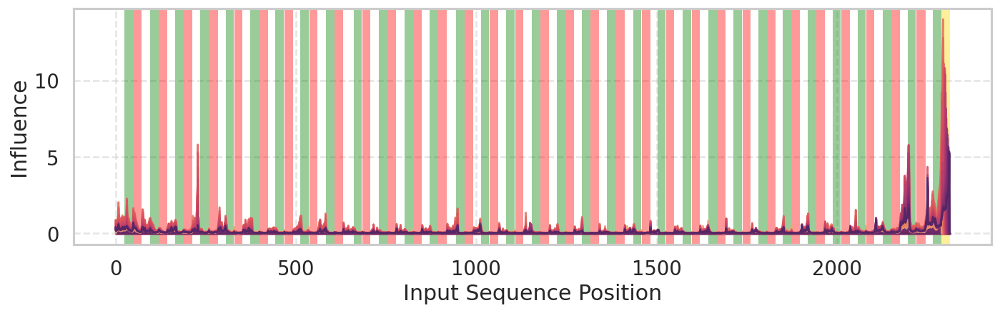

In [12]:
sns.set('talk', 'whitegrid')

fig = plot_scope_distribution_annotated(results, 'C', 'T','A', 24)
fig.savefig(f'{img_fldr}evo2_icl_dsplt_jcs_tata.png')

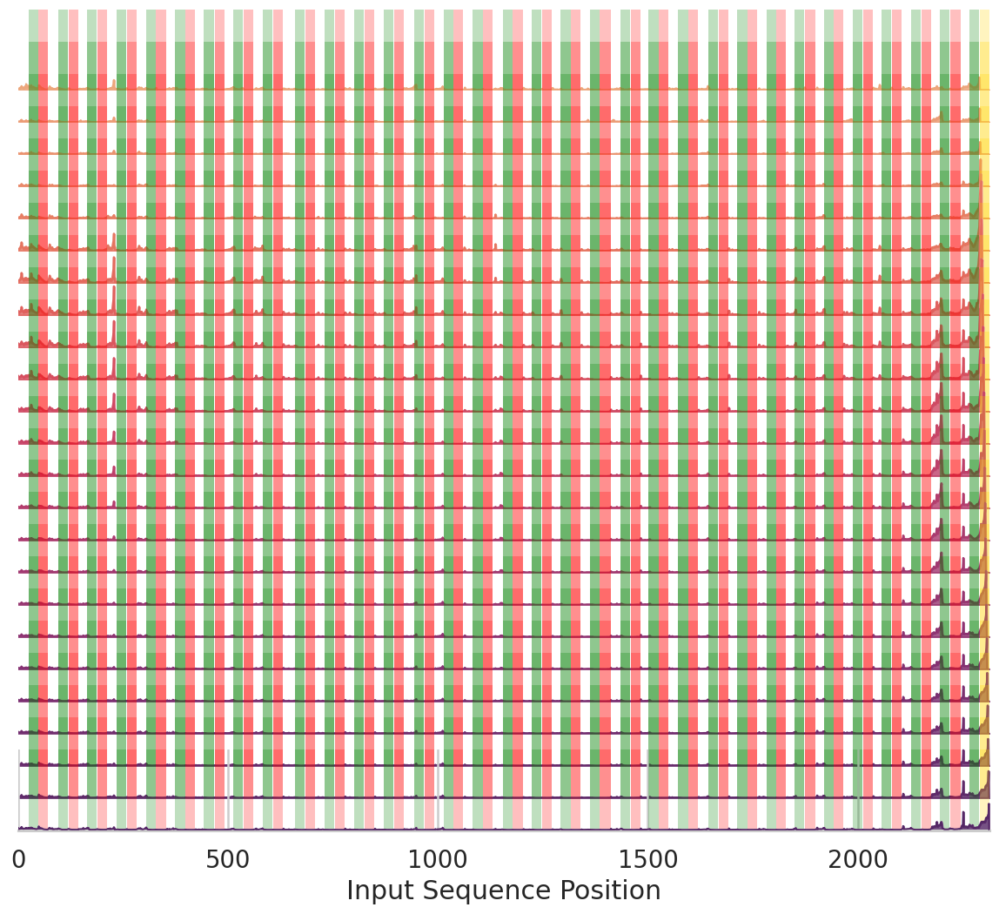

In [13]:
fig = plot_scope_ridge(results, 'C', 'T','A', 24)
fig.savefig(f'{img_fldr}evo2_icl_rgplt_jcs_tata.png')

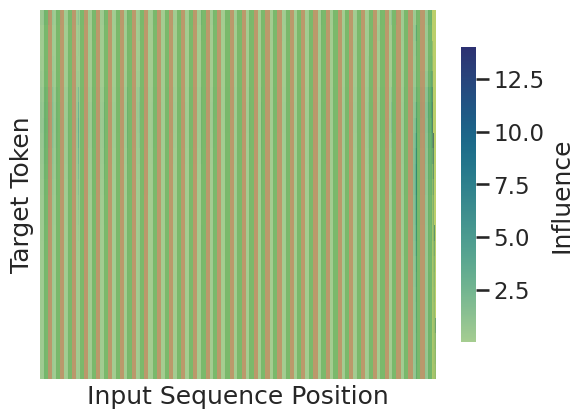

In [14]:
fig = plot_scope_heatmap(results, 'C', 'T','A', 24, cmap='crest')
plt.savefig(f'{img_fldr}evo2_icl_hm_jcs_tata.png')